DSP Laboratory Environment Ready!


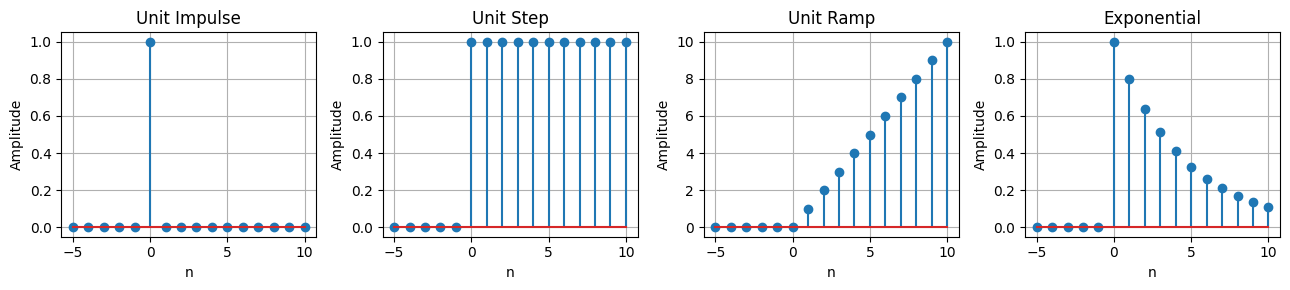

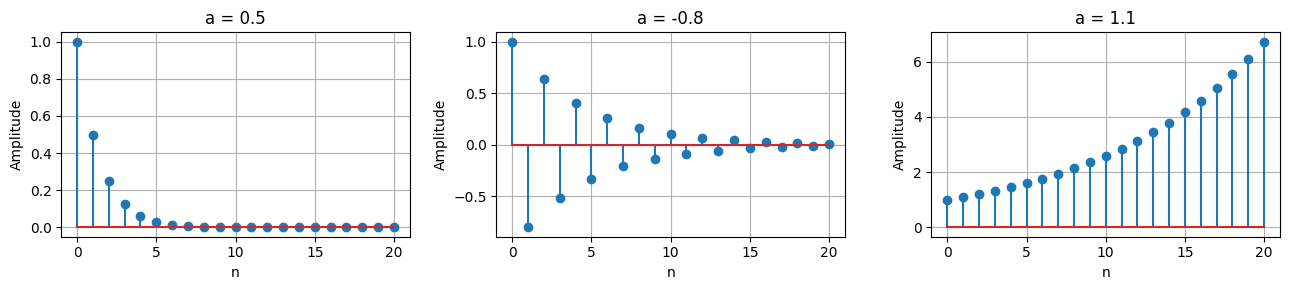

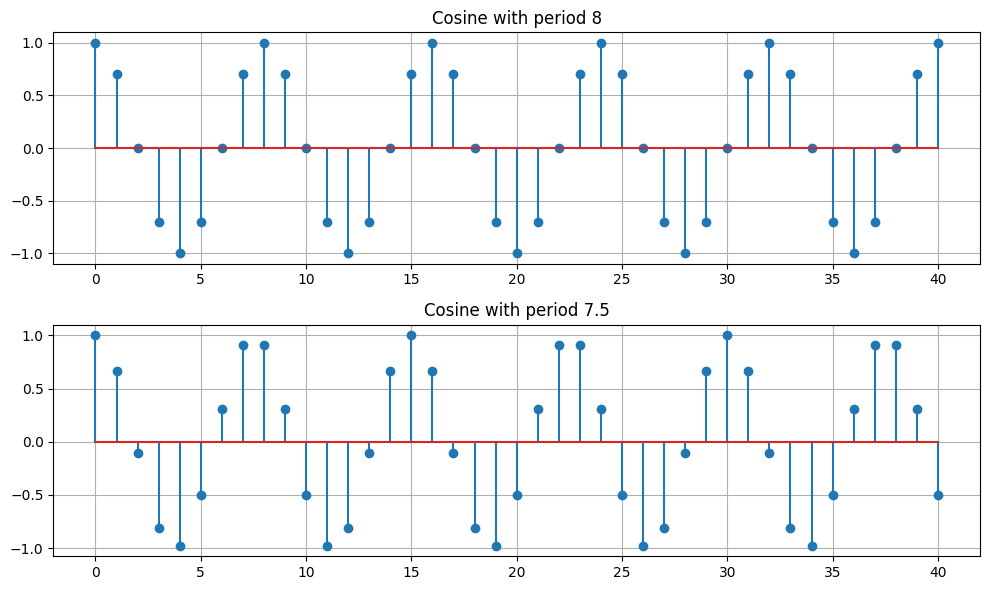

In [17]:
# WEEK 1 — LAB 0

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
import os

print("DSP Laboratory Environment Ready!")


# Generate discrete-time index
n = np.arange(-5, 11)

# Elementary signals
delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = 0.8**n * step

# Create four plots
fig, axes = plt.subplots(1, 4, figsize=(13, 3))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["Unit Impulse", "Unit Step", "Unit Ramp", "Exponential"]
):
    ax.stem(n, x)
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()


n = np.arange(0, 21)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))

for ax, a in zip(axes, a_values):
    x = (a**n)
    ax.stem(n, x)
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()


n = np.arange(0, 41)

x1 = np.cos(2*np.pi*n/8)
x2 = np.cos(2*np.pi*n/7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].stem(n, x1)
axes[0].set_title("Cosine with period 8")
axes[0].grid(True)

axes[1].stem(n, x2)
axes[1].set_title("Cosine with period 7.5")
axes[1].grid(True)

plt.tight_layout()
plt.show()



Question: Which one repeats exactly?

Answer: The first signal repeats exactly because its period is 8 samples, an integer. The second signal does not have an integer period and therefore is not periodic in discrete time.

In [21]:
from google.colab import files

uploaded = files.upload()

Saving my_voice.wav.mp3 to my_voice.wav.mp3


Sampling rate = 16000 Hz
Duration = 2.00 seconds
Samples = 32000


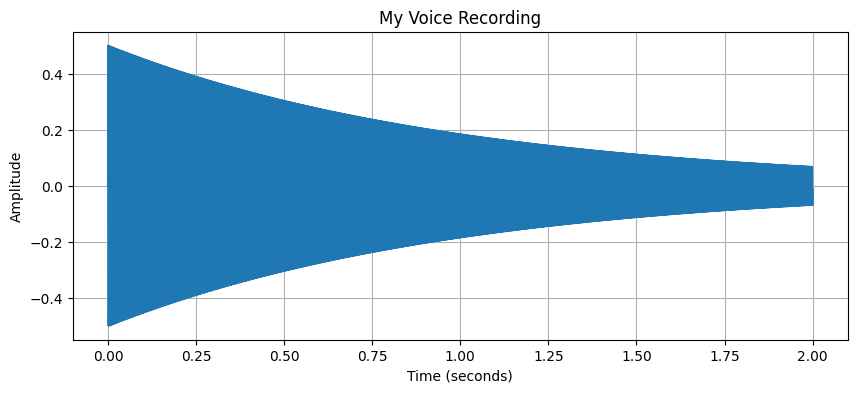

In [22]:

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

fname = "my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    if x.ndim > 1:
        x = x.astype(float).mean(axis=1)
    else:
        x = x.astype(float)

    peak = np.max(np.abs(x))
    if peak > 0:
        x = x / peak

else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t)*np.exp(-t)

t = np.arange(len(x)) / fs

print(f"Sampling rate = {fs} Hz")
print(f"Duration = {len(x)/fs:.2f} seconds")
print(f"Samples = {len(x)}")

plt.figure(figsize=(10, 4))
plt.plot(t, x)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("My Voice Recording")
plt.grid(True)
plt.show()


In [23]:

from IPython.display import Audio, display

display(Audio(x, rate=fs))


# ANSWERS TO PRE-LAB AND ANALYSIS QUESTIONS
## A. PRE-LAB QUESTION
**Question 1: List three devices you used today that contain Digital Signal Processing (DSP), and for each device name one signal it processes.**

**Answer**

i. **Smartphone:** A smartphone uses Digital Signal Processing to process voice signals during telephone calls. This helps improve voice clarity and reduce background noise.

ii. **Laptop:** A laptop uses DSP to process audio signals during music playback, video conferencing, and voice recording.

iii. **Bluetooth Headphones:** Bluetooth headphones use DSP to process audio signals, improve sound quality, and reduce unwanted background noise.

## B. ANALYSIS QUESTIONS

### i. What is the sampling rate of your phone's recording? How many numbers are needed to store one minute of it in mono?

**Answer:**

The sampling rate refers to the number of audio samples captured per second during recording. It is measured in Hertz (Hz).

For example, if a phone records audio at a sampling rate of 44,100 Hz, it captures 44,100 samples every second.

The total number of samples required to store one minute of mono audio can be calculated using the following formula:

[\
N=f_s\times T\
]

Where:

- (N) = Total number of samples.
- (f_s) = Sampling rate (44,100 Hz).
- (T) = Recording duration (60 seconds).

Substituting the values:

[\
N=44,100\times60\
]

[\
\boxed{N=2,646,000\text{ samples}}\
]

Therefore, a one-minute mono recording requires 2,646,000 sample values when recorded at a sampling rate of 44,100 Hz.

*Note: The actual sampling rate should be confirmed from the properties of the recorded audio file (my_voice.wav).*

### ii. Why is a stem plot more appropriate than a continuous line for (x(n))?

**Answer:**

A stem plot is more suitable for representing (x(n)) because it is a discrete-time signal consisting of individual sample values at specific integer time indices. Each sample is represented by a point and a vertical line connecting it to the horizontal axis.

A continuous line plot may give the impression that the signal has values at every point between the samples. However, a discrete-time signal is defined only at specific sampling instants.

Therefore, a stem plot provides a more accurate representation of discrete-time signals and makes it easier to identify and analyse individual sample values.

### iii. For (a=1.1), the exponential grows. Which property of a system would such a signal violate if it were an impulse response?

**Answer:**

An exponential signal with (a=1.1) increases in magnitude as the time index increases. If this signal were the impulse response of a discrete-time Linear Time-Invariant (LTI) system, it would violate the Bounded-Input Bounded-Output (BIBO) stability property.

For a discrete-time LTI system to be BIBO stable, the absolute sum of its impulse response must be finite:

[\
\sum\_{n=-\infty}^{\infty}|h(n)|<\infty\
]

For the given exponential signal:

[\
h(n)=1.1^n u(n)\
]

Since 1.1 is greater than one, the exponential signal increases as (n) increases. Consequently, the sum of the absolute values of the impulse response does not converge.

Therefore, the system is BIBO unstable because its impulse response does not satisfy the stability condition.

---

